In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
bad = df[df["TotalCharges"].str.strip() == ""]
print(len(bad))
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())

11


In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


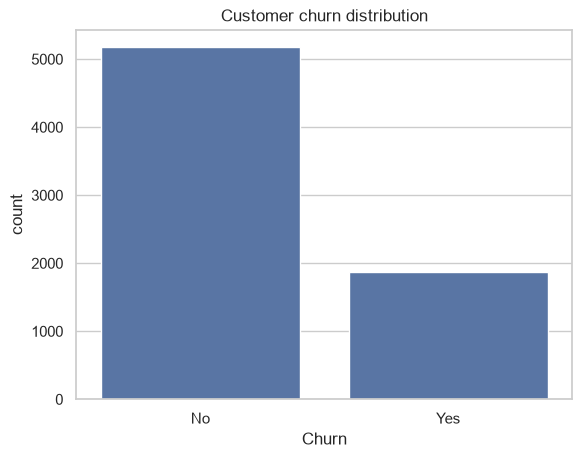

In [7]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

ax = sns.countplot(data=df, x="Churn")
ax.set_title("Customer churn distribution")
plt.savefig("../reports/figures/churn_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

The dataset is imbalanced: **1,869 of 7,043 customers (26.5%) churned** and **5,174 (73.5%) stayed**. A model that always predicted "No" would score about **73.5% accuracy** while catching no churners, so accuracy alone is a misleading metric and **recall, F1 and ROC-AUC** will be used instead.

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


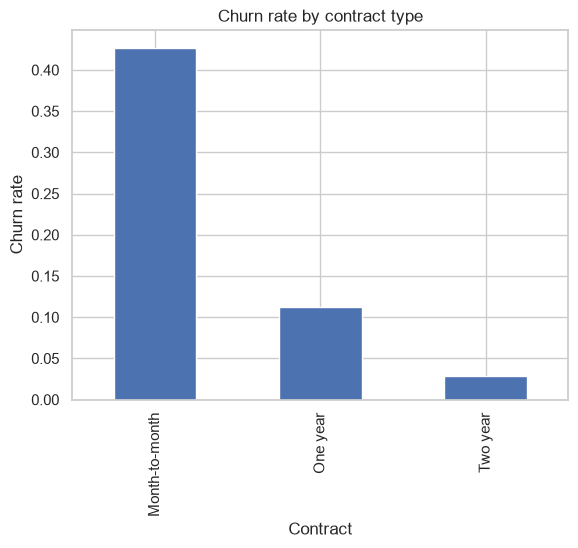

In [8]:
churn_by_contract = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean())
print(churn_by_contract.round(3))

ax = churn_by_contract.plot(kind="bar")
ax.set_ylabel("Churn rate")
ax.set_title("Churn rate by contract type")
plt.savefig("../reports/figures/churn_by_contract.png", dpi=200, bbox_inches="tight")
plt.show()

**Contract type is strongly linked to churn:** 42.7% of month-to-month customers churn, compared with 11.3% on one-year and 2.8% on two-year contracts. Month-to-month customers are roughly **15 times more likely** to leave than two-year customers.

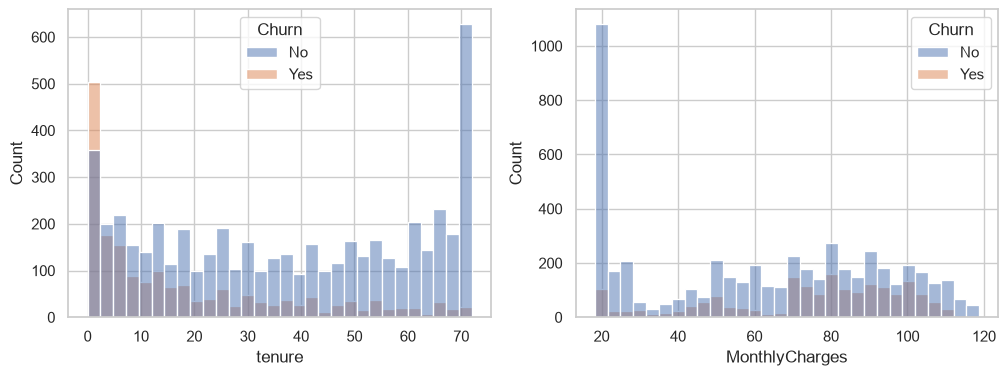

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[0])
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, ax=axes[1])
plt.savefig("../reports/figures/tenure_monthly_by_churn.png", dpi=200, bbox_inches="tight")
plt.show()

**Contract type is strongly linked to churn:** 42.7% of month-to-month customers churn, compared with 11.3% on one-year and 2.8% on two-year contracts. Month-to-month customers are roughly **15 times more likely** to leave than two-year customers.

In [10]:
print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median())

       tenure  MonthlyCharges
Churn                        
No       38.0          64.425
Yes      10.0          79.650


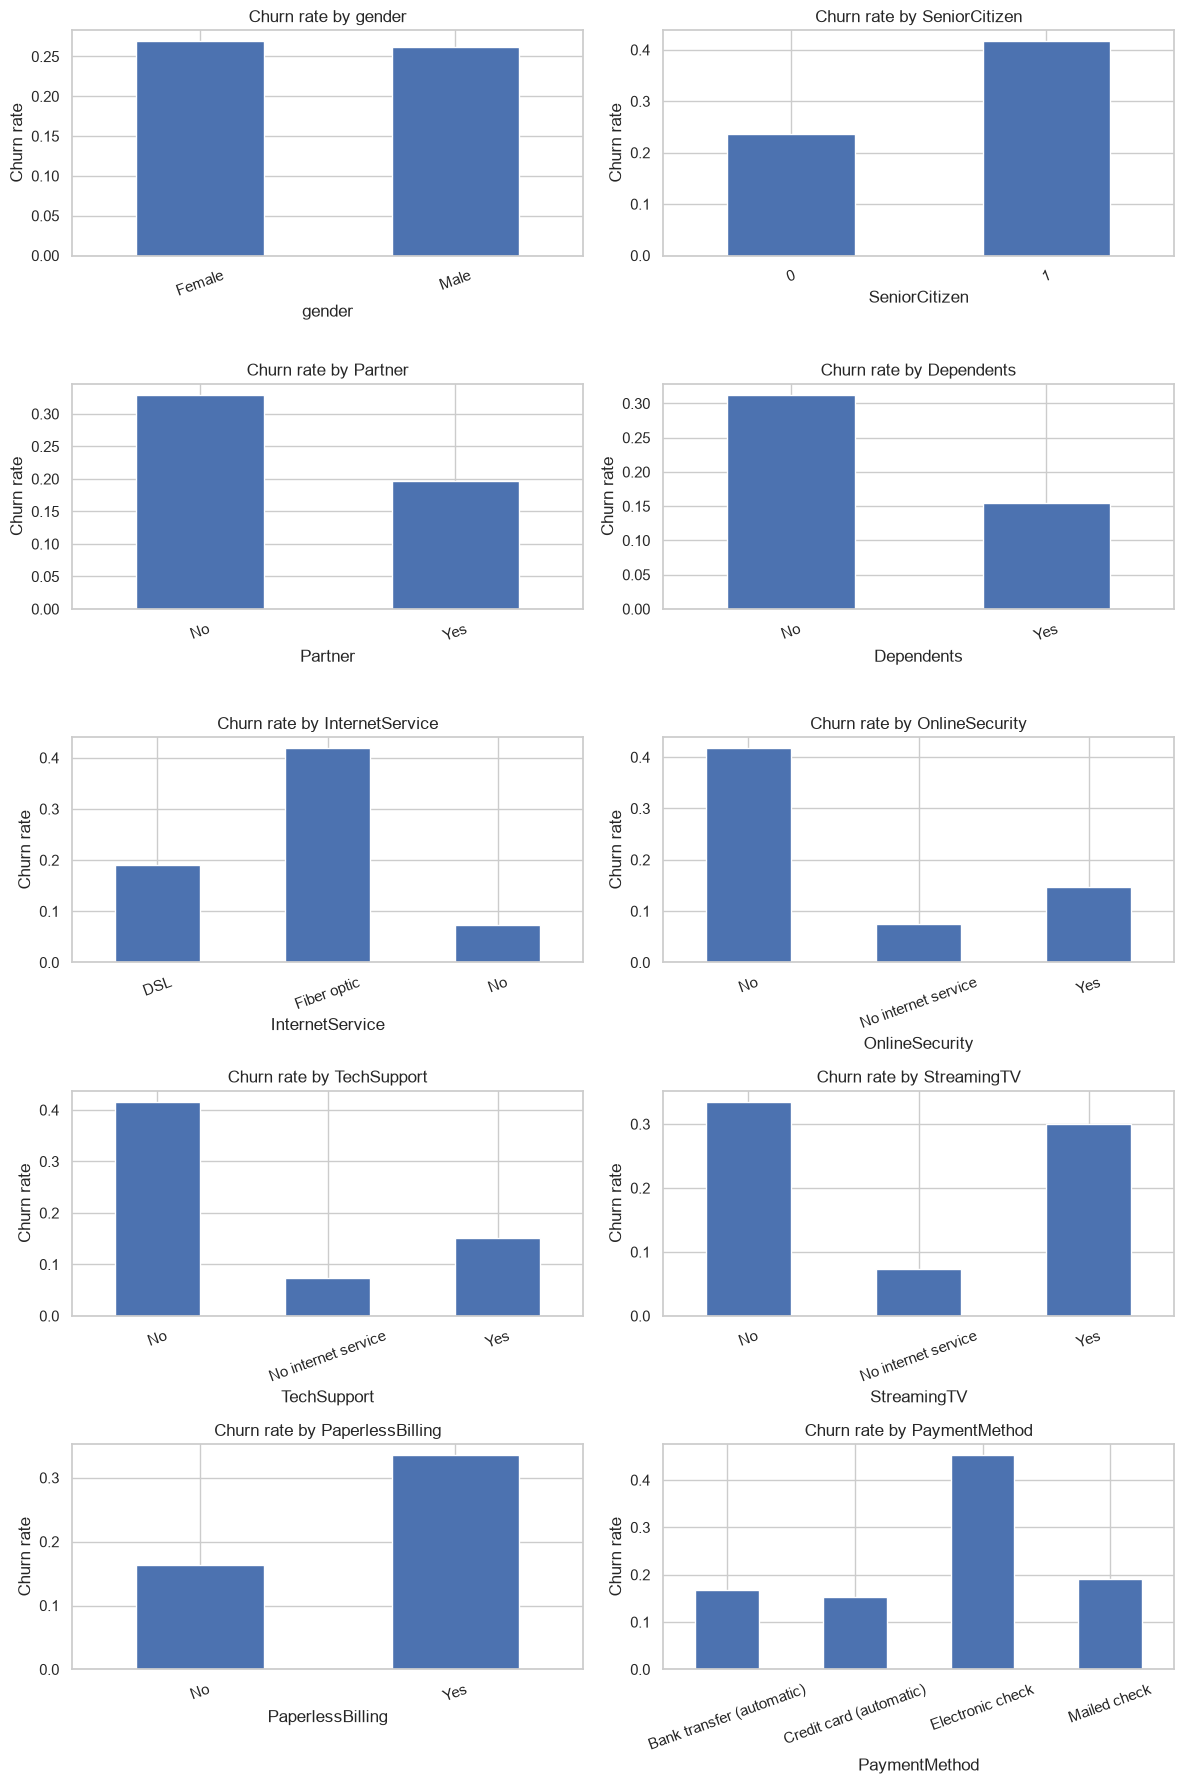

In [11]:
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "InternetService",
            "OnlineSecurity", "TechSupport", "StreamingTV", "PaperlessBilling", "PaymentMethod"]

fig, axes = plt.subplots(5, 2, figsize=(12, 18))
for ax, col in zip(axes.flatten(), cat_cols):
    rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean())
    rate.plot(kind="bar", ax=ax)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("../reports/figures/churn_by_categorical.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
for col in ["InternetService", "OnlineSecurity", "TechSupport", "StreamingTV", "PaymentMethod"]:
    print(df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).round(3), "\n")

InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64 

OnlineSecurity
No                     0.418
No internet service    0.074
Yes                    0.146
Name: Churn, dtype: float64 

TechSupport
No                     0.416
No internet service    0.074
Yes                    0.152
Name: Churn, dtype: float64 

StreamingTV
No                     0.335
No internet service    0.074
Yes                    0.301
Name: Churn, dtype: float64 

PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Electronic check             0.453
Mailed check                 0.191
Name: Churn, dtype: float64 



**Insights: churn by categorical features**

- **Internet service:** Fibre optic customers churn at about 41.9%, more than double the rate of DSL customers (about 19%) and far above customers with no internet service (about 7.4%), suggesting dissatisfaction with fibre plans, possibly price or service quality.
- **Online security:** Customers without online security churn at about 41.8%, compared with about 14.6% for those who have it, indicating that this add-on is strongly associated with retention.
- **Tech support:** Customers without tech support churn at about 41.6%, nearly three times the rate of those who have it (about 15.2%), suggesting that access to support helps keep customers.
- **Streaming TV:** Streaming TV has little effect on churn (about 33.5% without vs 30.1% with), so unlike security and support add-ons it is a weak predictor.
- **Payment method:** Electronic check users churn at about 45.3%, around 2.5 times the rate of customers using automatic payments or mailed checks (about 15-19%), so payment method is an informative feature.

In [15]:
for col in ["gender", "SeniorCitizen", "Partner", "Dependents", "PaperlessBilling"]:
    print(df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).round(3), "\n")

gender
Female    0.269
Male      0.262
Name: Churn, dtype: float64 

SeniorCitizen
0    0.236
1    0.417
Name: Churn, dtype: float64 

Partner
No     0.330
Yes    0.197
Name: Churn, dtype: float64 

Dependents
No     0.313
Yes    0.155
Name: Churn, dtype: float64 

PaperlessBilling
No     0.163
Yes    0.336
Name: Churn, dtype: float64 



- **Gender:** Gender has almost no effect on churn (female 26.9% vs male 26.2%), so it is a weak predictor and a candidate for removal on fairness grounds.
- **Senior citizens:** Senior citizens churn at 41.7%, almost double the rate of non-seniors (23.6%).
- **Household (partner and dependents):** Customers without a partner churn at 33.0% vs 19.7% with one, and those without dependents churn at 31.3% vs 15.5% with them, suggesting that customers with a household attached are more likely to stay.
- **Paperless billing:** Customers on paperless billing churn at 33.6%, about double the rate of those on paper billing (16.3%).

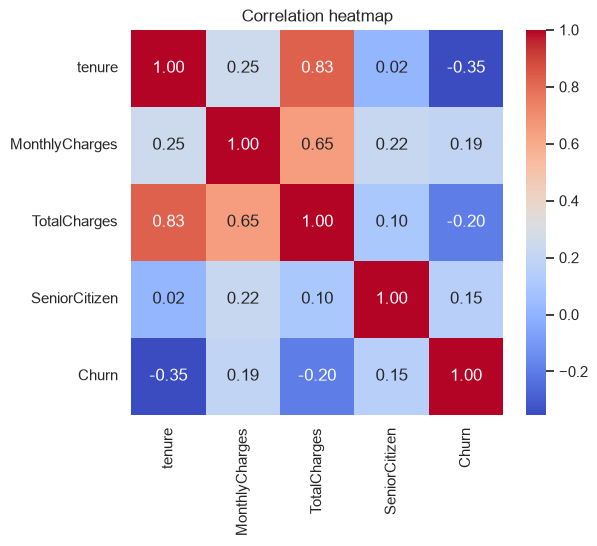

In [12]:
df_corr = df.copy()
df_corr["Churn"] = (df_corr["Churn"] == "Yes").astype(int)

plt.figure(figsize=(6, 5))
sns.heatmap(df_corr[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median())

       tenure  MonthlyCharges
Churn                        
No       38.0          64.425
Yes      10.0          79.650
